In [1]:
# FINAL MODEL

In [2]:
## 1. Load original data and reserve the test set

In [3]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay

paths = [Path('wine_raw.csv'), Path('../01_Data_Collection/wine_raw.csv'), Path('01_Data_Collection/wine_raw.csv'), Path('Wine_ML_Assignment/01_Data_Collection/wine_raw.csv')]
found = next((x for x in paths if x.exists()), None)
if found:
    df = pd.read_csv(found)
    print('Loaded:', found)
else:
    wine = load_wine(as_frame=True)
    df = wine.frame.rename(columns={'target':'class'})
    print('CSV not found; loaded the same UCI Wine dataset from sklearn.')
assert 'class' in df.columns, 'Expected a class column.'
X, y = df.drop(columns='class'), df['class']
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)
print('Train:',X_train.shape,'Test:',X_test.shape,'Classes:',sorted(y.unique()))

Loaded: wine_raw.csv
Train: (142, 13) Test: (36, 13) Classes: [np.int64(0), np.int64(1), np.int64(2)]


In [4]:
# GRIDSEARCH CV MODEL

In [5]:
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
models = {
 'Logistic Regression':(LogisticRegression(max_iter=3000,random_state=42),{'select__k':[5,10,13],'model__C':[0.1,1,10]}),
 'SVM':(SVC(),{'select__k':[5,10,13],'model__C':[0.1,1,10],'model__kernel':['linear','rbf']}),
 'Random Forest':(RandomForestClassifier(random_state=42),{'select__k':[5,10,13],'model__n_estimators':[100,200],'model__max_depth':[None,5]})
}
def search_best(target):
    records=[]; winner=None; winner_name=None
    for name,(est,grid) in models.items():
        pipeline=Pipeline([('impute',SimpleImputer(strategy='median')),
                           ('scale',StandardScaler()),
                           ('select',SelectKBest(f_classif)),('model',est)])
        search=GridSearchCV(pipeline,grid,scoring='f1_macro',cv=cv,n_jobs=-1,refit=True)
        search.fit(X_train,target)
        records.append({'Algorithm':name,'CV Macro F1':search.best_score_,'Best Parameters':str(search.best_params_)})
        if winner is None or search.best_score_>winner.best_score_:
            winner,winner_name=search,name
    return pd.DataFrame(records),winner,winner_name

In [6]:
## 3. Method A — Preprocess Input (X) only

In [7]:
scores_A,best_A,name_A=search_best(y_train)
print('Method A: best algorithm =',name_A)
display(scores_A)

Method A: best algorithm = SVM


,Algorithm,CV Macro F1,Best Parameters
0,Logistic Regression,0.979637,"{'model__C': 1, 'select__k': 13}"
1,SVM,0.992657,"{'model__C': 10, 'model__kernel': 'rbf', 'sele..."
2,Random Forest,0.978923,"{'model__max_depth': None, 'model__n_estimator..."


In [8]:
## 4. Method B — Preprocess Input (X) and Output (y)

In [9]:
encoder=LabelEncoder()
y_train_B=encoder.fit_transform(y_train)
y_test_B=encoder.transform(y_test)
scores_B,best_B,name_B=search_best(y_train_B)
print('Method B: best algorithm =',name_B)
print('Label classes:',encoder.classes_)
print('Target unchanged after encoding:',np.array_equal(np.asarray(y_train),y_train_B))
display(scores_B)

Method B: best algorithm = SVM
Label classes: [0 1 2]
Target unchanged after encoding: True


,Algorithm,CV Macro F1,Best Parameters
0,Logistic Regression,0.979637,"{'model__C': 1, 'select__k': 13}"
1,SVM,0.992657,"{'model__C': 10, 'model__kernel': 'rbf', 'sele..."
2,Random Forest,0.978923,"{'model__max_depth': None, 'model__n_estimator..."


In [10]:
## 5. Compare training cross-validation results

In [11]:
cv_comparison=scores_A[['Algorithm','CV Macro F1']].merge(scores_B[['Algorithm','CV Macro F1']],on='Algorithm',suffixes=(' — X only',' — X + y'))
display(cv_comparison.round(4))
use_A = best_A.best_score_ >= best_B.best_score_  # tie -> simpler X-only approach
final_model = best_A.best_estimator_ if use_A else best_B.best_estimator_
final_encoder = None if use_A else encoder
print('Selected approach:', 'A — X only' if use_A else 'B — X + y')
print('Selected algorithm:',name_A if use_A else name_B)
print('Selected CV macro F1:',round(max(best_A.best_score_,best_B.best_score_),4))

,Algorithm,CV Macro F1 — X only,CV Macro F1 — X + y
0,Logistic Regression,0.9796,0.9796
1,SVM,0.9927,0.9927
2,Random Forest,0.9789,0.9789


Selected approach: A — X only
Selected algorithm: SVM
Selected CV macro F1: 0.9927


In [12]:
## 6. Final test evaluation — Both methods

In [13]:
def evaluate(name,estimator,true,pred):
    return {'Method':name,'Accuracy':accuracy_score(true,pred),
            'Precision (macro)':precision_score(true,pred,average='macro',zero_division=0),
            'Recall (macro)':recall_score(true,pred,average='macro',zero_division=0),
            'F1 (macro)':f1_score(true,pred,average='macro',zero_division=0)}
pred_A=best_A.predict(X_test)
pred_B_encoded=best_B.predict(X_test)
pred_B=encoder.inverse_transform(pred_B_encoded)
results=pd.DataFrame([evaluate('A — Input only',best_A,y_test,pred_A),
                      evaluate('B — Input + Output',best_B,y_test,pred_B)])
display(results.round(4))
print('Method A classification report:')
print(classification_report(y_test,pred_A,zero_division=0))
print('Method B classification report:')
print(classification_report(y_test,pred_B,zero_division=0))

,Method,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,A — Input only,0.9444,0.9583,0.9333,0.9407
1,B — Input + Output,0.9444,0.9583,0.9333,0.9407


Method A classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.88      1.00      0.93        14
           2       1.00      0.80      0.89        10

    accuracy                           0.94        36
   macro avg       0.96      0.93      0.94        36
weighted avg       0.95      0.94      0.94        36

Method B classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.88      1.00      0.93        14
           2       1.00      0.80      0.89        10

    accuracy                           0.94        36
   macro avg       0.96      0.93      0.94        36
weighted avg       0.95      0.94      0.94        36



In [14]:
## 7. Confusion matrices — Both methods

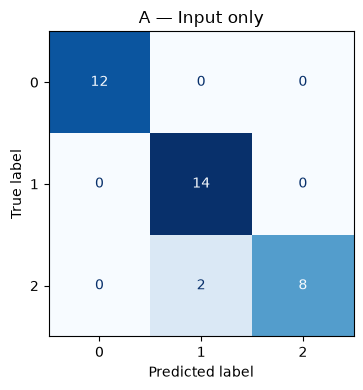

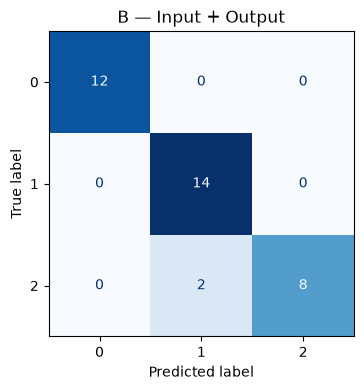

In [15]:
for label,pred in [('A — Input only',pred_A),('B — Input + Output',pred_B)]:
    fig,ax=plt.subplots(figsize=(5,4))
    ConfusionMatrixDisplay.from_predictions(y_test,pred,ax=ax,cmap='Blues',colorbar=False)
    ax.set_title(label)
    plt.tight_layout();plt.show()

In [16]:
## 8. Save the final model and make a sample prediction

In [17]:
output=Path('wine_final_model_corrected.joblib')
artifact={'pipeline':final_model,'label_encoder':final_encoder,
          'feature_columns':list(X.columns),
          'method':'Input only' if use_A else 'Input + Output',
          'algorithm':name_A if use_A else name_B}
joblib.dump(artifact,output)
loaded=joblib.load(output)
sample=X_test.iloc[[0]][loaded['feature_columns']]
raw_prediction=loaded['pipeline'].predict(sample)
prediction=raw_prediction if loaded['label_encoder'] is None else loaded['label_encoder'].inverse_transform(raw_prediction)
print('Saved:',output.resolve())
print('Sample predicted class:',prediction[0],'Actual class:',y_test.iloc[0])

Saved: C:\HOPE AI\AI TAMIL COURSE\ML & DATA SCIENCE  ADVANCED TECHNIQUES\5.Final Model\wine_final_model_corrected.joblib
Sample predicted class: 0 Actual class: 0
